# Fundamentals of Data Science: Case Studies 3 and 6

| | |
|---|---|
| **Case Study 3** | Predicting Titanic Survival with Logistic Regression |
| **Case Study 6** | Comparative Analysis of Classification Algorithms for Bank Marketing Prediction |
| **Name** | Nikhil Kotte |
| **Roll No** | 160124733191 |
| **Section** | CSE-3 |
| **Year** | III Year, V Semester (2026-27) |
| **Subject** | Fundamentals of Data Science |
| **Faculty** | Dr. S. Durga Devi, Assistant Professor |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |

## Objective

Part A predicts Titanic survival with logistic regression. I add a few new features, tune the model and deploy it as a Streamlit app.
Part B compares four classifiers (Logistic Regression, Decision Tree, KNN, Random Forest) on bank marketing data to predict who will subscribe to a term deposit.

**Purpose:** Import the libraries and create the folders for figures, results and the saved model.

In [1]:
import json
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
for folder in ["figures", "results", "3/model"]:
    os.makedirs(folder, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)
print("pandas", pd.__version__)

pandas 3.1.0


**Observation:** All libraries loaded (pandas 3.1.0) and the folders were created.

# Part A: Case Study 3, Titanic Survival with Logistic Regression

## A1. Data Exploration

**Purpose:** Load the Titanic data and look at its shape and first rows.

In [2]:
titanic = pd.read_csv("3/titanic.csv")
print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** The data has 891 passengers and 12 columns. `Survived` is the target (1 = survived). Cabin already shows missing values in the first rows.

**Purpose:** Check data types and non-null counts.

In [3]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Observation:** Age (714 of 891), Cabin (204 of 891) and Embarked (889 of 891) have missing values. The other columns are complete.

**Purpose:** Summary statistics for the numeric and text columns.

In [4]:
num_summary = titanic[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].describe().T.round(2)
num_summary.to_csv("results/cs3_summary_numeric.csv")
print(num_summary)
print()
print(titanic[["Sex", "Embarked", "Ticket", "Cabin", "Name"]].describe().T)

          count   mean    std   min    25%    50%   75%     max
Survived  891.0   0.38   0.49  0.00   0.00   0.00   1.0    1.00
Pclass    891.0   2.31   0.84  1.00   2.00   3.00   3.0    3.00
Age       714.0  29.70  14.53  0.42  20.12  28.00  38.0   80.00
SibSp     891.0   0.52   1.10  0.00   0.00   0.00   1.0    8.00
Parch     891.0   0.38   0.81  0.00   0.00   0.00   0.0    6.00
Fare      891.0  32.20  49.69  0.00   7.91  14.45  31.0  512.33

         count unique                      top freq
Sex        891      2                     male  577
Embarked   889      3                        S  644
Ticket     891    681                   347082    7
Cabin      204    147                       G6    4
Name       891    891  Braund, Mr. Owen Harris    1


**Observation:** About 38% of passengers survived (mean of Survived = 0.38). The median age is 28. Fare is very spread out (median 14.45, max 512.33). There are 577 males, and most people boarded at Southampton (644). Name and Ticket have almost all unique values, so they can't be used directly.

**Purpose:** Count missing values in each column.

In [5]:
missing = pd.DataFrame({"missing": titanic.isna().sum(), "percent": (titanic.isna().mean() * 100).round(2)})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing.to_csv("results/cs3_missing.csv")
missing

,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


**Observation:** Cabin is missing for 77.10% of passengers, Age for 19.87% and Embarked for only 2 rows. Cabin is too empty to fill in, so I only use whether it is known. Age and Embarked will be imputed.

**Purpose:** Overall survival rate and survival rate by Sex, Pclass and Embarked.

In [6]:
print("Overall survival rate:", round(titanic["Survived"].mean() * 100, 2), "%")
rows = []
for col in ["Sex", "Pclass", "Embarked"]:
    g = titanic.groupby(col)["Survived"].agg(["count", "mean"])
    for group, n, rate in zip(g.index, g["count"], g["mean"]):
        rows.append([col, str(group), n, round(rate * 100, 2)])
survival_rates = pd.DataFrame(rows, columns=["feature", "group", "passengers", "survival_rate"])
survival_rates.to_csv("results/cs3_survival_rates.csv", index=False)
survival_rates

Overall survival rate: 38.38 %


,feature,group,passengers,survival_rate
0,Sex,female,314,74.20
1,Sex,male,577,18.89
2,Pclass,1,216,62.96
3,Pclass,2,184,47.28
4,Pclass,3,491,24.24
5,Embarked,C,168,55.36
6,Embarked,Q,77,38.96
7,Embarked,S,644,33.70


**Observation:** 38.38% survived overall. Women survived far more often than men (74.20% vs 18.89%). Survival drops with class: 62.96% in 1st, 47.28% in 2nd, 24.24% in 3rd. Cherbourg passengers survived the most (55.36%).

**Purpose:** Histograms of Age and Fare.

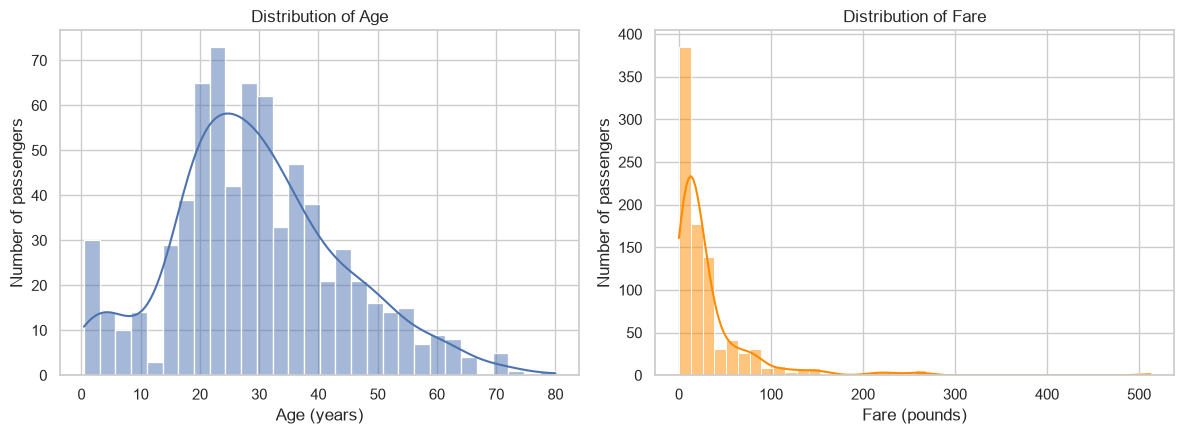

Skewness  Age: 0.39  Fare: 4.79


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(titanic["Age"].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")
sns.histplot(titanic["Fare"], bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of Fare")
axes[1].set_xlabel("Fare (pounds)")
axes[1].set_ylabel("Number of passengers")
plt.tight_layout()
plt.savefig("figures/cs3_01_age_fare_hist.png", dpi=150)
plt.show()
print("Skewness  Age:", round(titanic["Age"].skew(), 2), " Fare:", round(titanic["Fare"].skew(), 2))

**Observation:** Age is roughly symmetric (skew 0.39) with most people between 20 and 40. Fare is strongly right skewed (skew 4.79), so the median is a better fill value than the mean.

**Purpose:** Box plots of Age and Fare by survival.

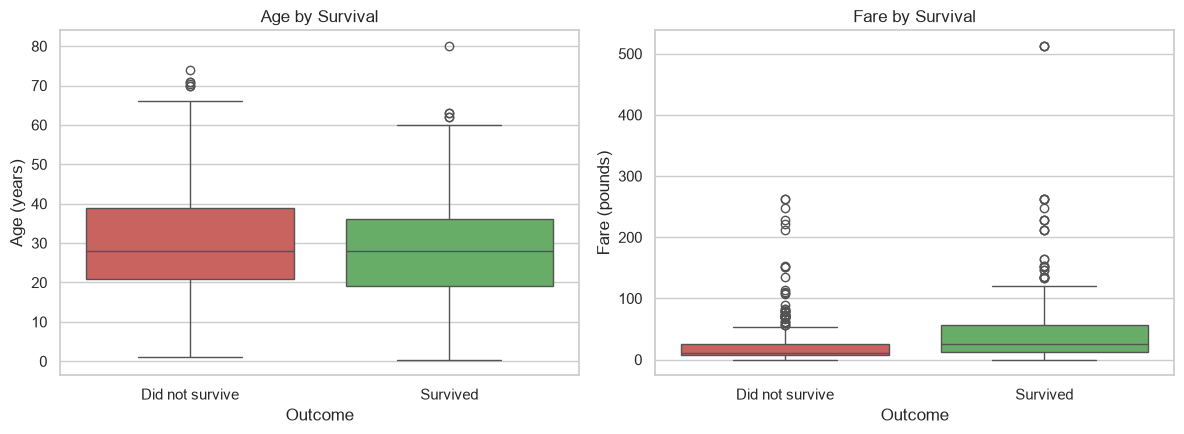

                  Age  Fare
Outcome                    
Did not survive  28.0  10.5
Survived         28.0  26.0


In [8]:
titanic["Outcome"] = titanic["Survived"].map({0: "Did not survive", 1: "Survived"})
order = ["Did not survive", "Survived"]
colors = ["#d9534f", "#5cb85c"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in [(axes[0], "Age", "Age (years)"), (axes[1], "Fare", "Fare (pounds)")]:
    sns.boxplot(data=titanic, x="Outcome", y=col, order=order, hue="Outcome", palette=colors, legend=False, ax=ax)
    ax.set_title(f"{col} by Survival")
    ax.set_xlabel("Outcome")
    ax.set_ylabel(label)
plt.tight_layout()
plt.savefig("figures/cs3_02_age_fare_box.png", dpi=150)
plt.show()
print(titanic.groupby("Outcome")[["Age", "Fare"]].median())

**Observation:** The median age is 28 in both groups, but survivors paid more (median fare 26.0 vs 10.5). This links to class.

**Purpose:** Count plots of survival by Sex and by Pclass.

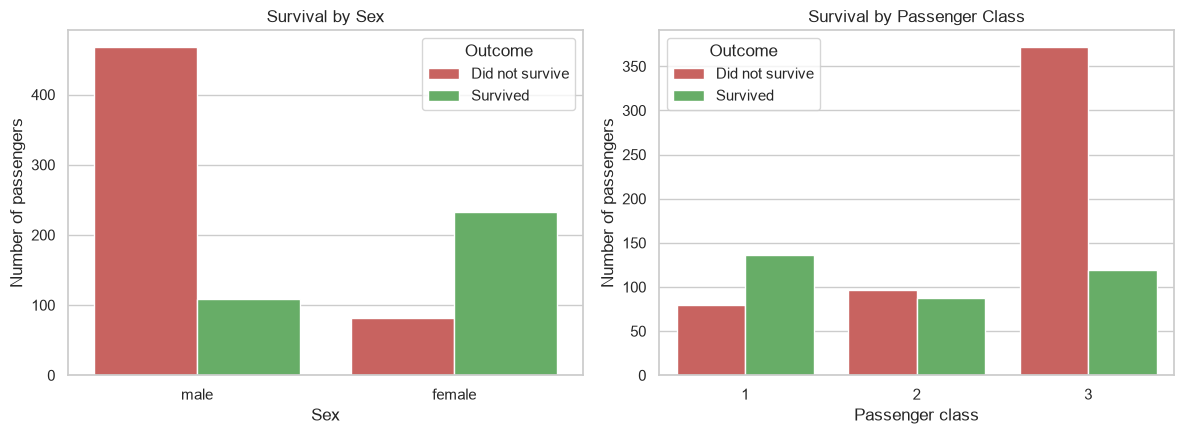

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=titanic, x="Sex", hue="Outcome", hue_order=order, palette=colors, ax=axes[0])
axes[0].set_title("Survival by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Number of passengers")
sns.countplot(data=titanic, x="Pclass", hue="Outcome", hue_order=order, palette=colors, ax=axes[1])
axes[1].set_title("Survival by Passenger Class")
axes[1].set_xlabel("Passenger class")
axes[1].set_ylabel("Number of passengers")
plt.tight_layout()
plt.savefig("figures/cs3_03_survival_sex_class.png", dpi=150)
plt.show()

**Observation:** Most women survived and most men did not. 1st class is the only class with more survivors than deaths, and 3rd class has by far the most deaths.

**Purpose:** Pair plot of the numeric features coloured by survival.

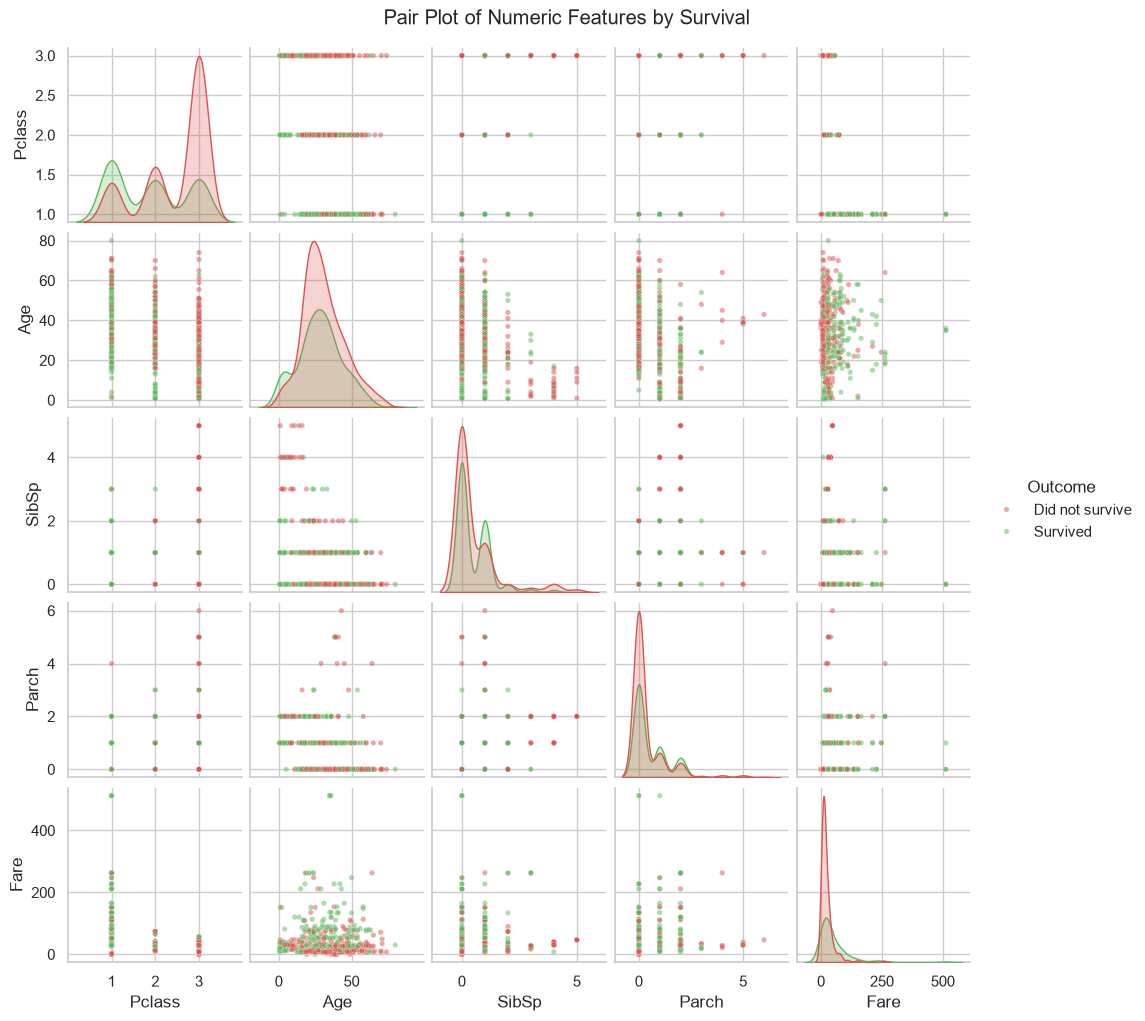

In [10]:
g = sns.pairplot(titanic[["Pclass", "Age", "SibSp", "Parch", "Fare", "Outcome"]].dropna(), hue="Outcome",
                 hue_order=order, palette=colors, plot_kws={"alpha": 0.5, "s": 15}, height=2.0)
g.fig.suptitle("Pair Plot of Numeric Features by Survival", y=1.02)
g.savefig("figures/cs3_04_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Survivors cluster at higher fares and in 1st class, and there is a small group of surviving young children. The two classes overlap a lot, so the numeric features alone can't separate them.

### New features

- **Title** from the name (Mr, Mrs, Miss, Master, others grouped as Rare). It shows sex and also age group (Master = boy).
- **FamilySize** = SibSp + Parch + 1.
- **IsAlone** = 1 if FamilySize is 1.
- **HasCabin** = 1 if a cabin number is recorded. Cabin is mostly missing, but whether it is known might still matter.

**Purpose:** Create the four new features and check the survival rate for each.

In [11]:
titanic["Title"] = titanic["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
titanic["Title"] = titanic["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
titanic.loc[~titanic["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
titanic["FamilySize"] = titanic["SibSp"] + titanic["Parch"] + 1
titanic["IsAlone"] = (titanic["FamilySize"] == 1).astype(int)
titanic["HasCabin"] = titanic["Cabin"].notna().astype(int)

rows = []
for col in ["Title", "FamilySize", "IsAlone", "HasCabin"]:
    values = titanic[col].clip(upper=5) if col == "FamilySize" else titanic[col]
    g = titanic.groupby(values)["Survived"].agg(["count", "mean"])
    for group, n, rate in zip(g.index, g["count"], g["mean"]):
        label = "5+" if col == "FamilySize" and group == 5 else str(group)
        rows.append([col, label, n, round(rate * 100, 2)])
new_rates = pd.DataFrame(rows, columns=["feature", "group", "passengers", "survival_rate"])
new_rates.to_csv("results/cs3_new_feature_rates.csv", index=False)
new_rates

,feature,group,passengers,survival_rate
0,Title,Master,40,57.50
1,Title,Miss,185,70.27
2,Title,Mr,517,15.67
3,Title,Mrs,126,79.37
4,Title,Rare,23,34.78
5,FamilySize,1,537,30.35
6,FamilySize,2,161,55.28
7,FamilySize,3,102,57.84
8,FamilySize,4,29,72.41
9,FamilySize,5+,62,16.13


**Observation:** Title separates passengers well: Mr 15.67%, Master (boys) 57.50%, Miss 70.27%, Mrs 79.37%, Rare 34.78%. Small families of 2 to 4 survived more (55% to 72%) than people alone (30.35%) or families of 5+ (16.13%). A recorded cabin goes with 66.67% survival against 29.99%.

**Purpose:** Bar charts of survival rate for the new features.

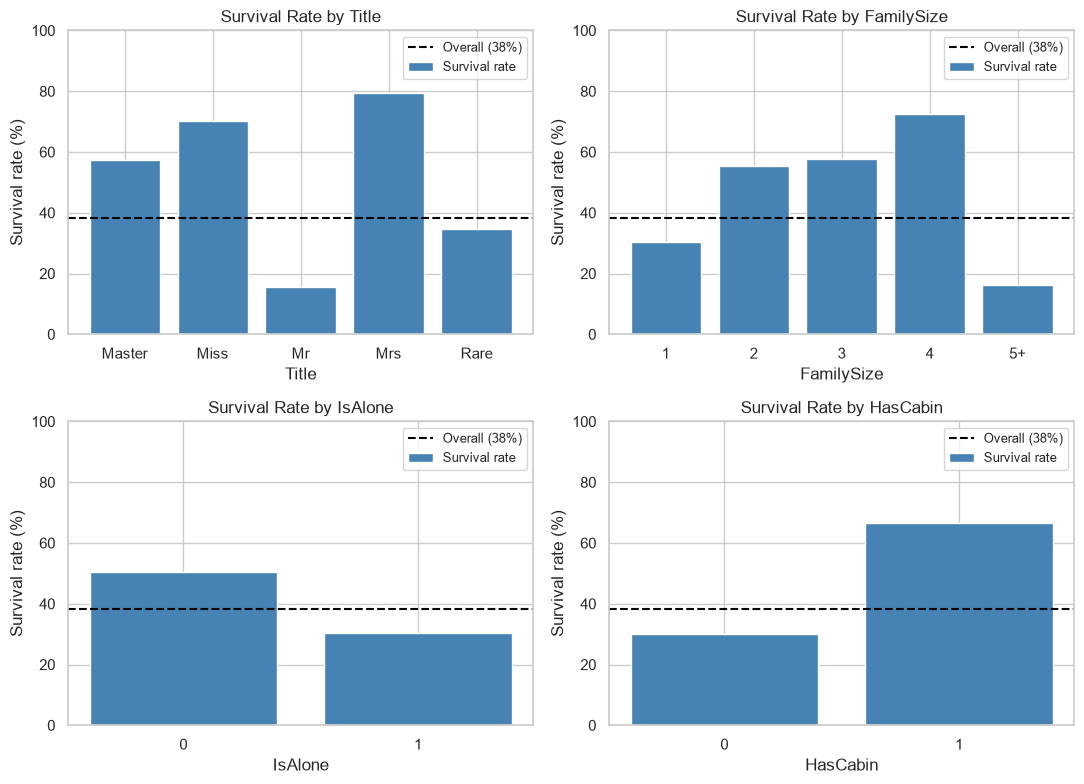

In [12]:
overall = titanic["Survived"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["Title", "FamilySize", "IsAlone", "HasCabin"]):
    t = new_rates[new_rates["feature"] == col]
    ax.bar(t["group"], t["survival_rate"], color="steelblue", label="Survival rate")
    ax.axhline(overall, color="black", ls="--", label=f"Overall ({overall:.0f}%)")
    ax.set_title(f"Survival Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Survival rate (%)")
    ax.set_ylim(0, 100)
    ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/cs3_05_new_features.png", dpi=150)
plt.show()

**Observation:** All four new features have groups clearly above or below the 38% line. Title and HasCabin show the biggest differences. FamilySize goes up and then down.

**Purpose:** Correlation heatmap of the numeric columns, including the new ones.

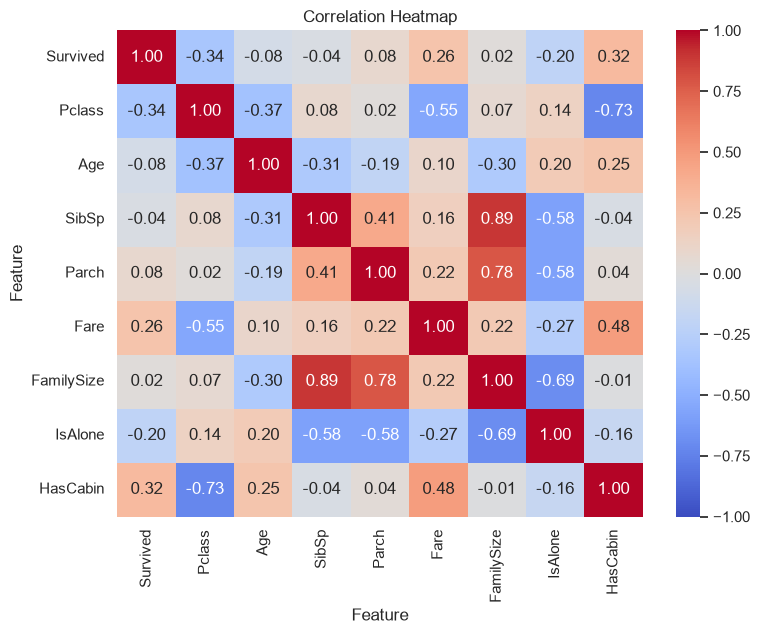

Pclass       -0.338
IsAlone      -0.203
Age          -0.077
SibSp        -0.035
FamilySize    0.017
Parch         0.082
Fare          0.257
HasCabin      0.317
Name: Survived, dtype: float64


In [13]:
corr = titanic[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/cs3_06_correlation.png", dpi=150)
plt.show()
corr.round(3).to_csv("results/cs3_correlation.csv")
print(corr["Survived"].drop("Survived").sort_values().round(3))

**Observation:** Pclass (-0.338) and HasCabin (0.317) have the strongest correlation with survival, followed by Fare (0.257) and IsAlone (-0.203). FamilySize is almost 0 (0.017) because its effect goes up and then down, which a correlation can't capture.

## A2. Data Preprocessing

- PassengerId, Name, Ticket and Cabin are not used directly. Name is only used for Title and Cabin only for HasCabin.
- **Baseline model:** the 7 original features (Pclass, Sex, Age, SibSp, Parch, Fare, Embarked).
- **New model:** Pclass, Age, Fare, Embarked, Title, FamilySize, IsAlone, HasCabin. SibSp and Parch are replaced by FamilySize. Sex is not used again because Title already contains it.
- Inside the Pipeline: median imputation and scaling for numbers, most-frequent imputation and one-hot encoding for categories. Everything is fitted on the training data only.

**Purpose:** Make a stratified 80:20 split and build the two pipelines.

In [14]:
X = titanic.drop(columns="Survived")
y = titanic["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], " Test:", X_test.shape[0])


def num_pipe():
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])


def cat_pipe():
    return Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))])


baseline = Pipeline([
    ("prep", ColumnTransformer([("num", num_pipe(), ["Pclass", "Age", "SibSp", "Parch", "Fare"]),
                                ("cat", cat_pipe(), ["Sex", "Embarked"])])),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

new_model = Pipeline([
    ("prep", ColumnTransformer([("num", num_pipe(), ["Pclass", "Age", "Fare", "FamilySize"]),
                                ("flags", "passthrough", ["IsAlone", "HasCabin"]),
                                ("cat", cat_pipe(), ["Embarked", "Title"])])),
    ("clf", LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE))])

Train: 712  Test: 179


**Observation:** 712 passengers are used for training and 179 for testing. Both pipelines are defined but not fitted yet.

## A3. Model Building

**Purpose:** Train the baseline model and check its 5-fold cross-validation accuracy on the training set.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
base_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="accuracy")
print("Fold accuracies:", base_cv.round(4))
print("Mean CV accuracy:", round(base_cv.mean(), 4), " std:", round(base_cv.std(), 4))

Fold accuracies: [0.7972 0.7972 0.8028 0.7465 0.831 ]
Mean CV accuracy: 0.7949  std: 0.0273


**Observation:** The baseline's 5-fold CV accuracy is 0.7949 (std 0.0273). The folds range from 0.7465 to 0.8310, so it is fairly stable.

**Purpose:** Tune C and the penalty (L1 or L2) of the new model with GridSearchCV, using 5-fold CV and ROC-AUC. In scikit-learn 1.9 the penalty is set with `l1_ratio` (0 = L2, 1 = L1).

In [16]:
grid = GridSearchCV(new_model,
                    {"clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100], "clf__l1_ratio": [0, 1]},
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
tuned = grid.best_estimator_
best_C = grid.best_params_["clf__C"]
best_penalty = "L1" if grid.best_params_["clf__l1_ratio"] == 1 else "L2"
print("Best C:", best_C, " Best penalty:", best_penalty, " Best CV ROC-AUC:", round(grid.best_score_, 4))

res = pd.DataFrame(grid.cv_results_)
res = pd.DataFrame({"C": res["param_clf__C"], "penalty": res["param_clf__l1_ratio"].map({0: "L2", 1: "L1"}),
                    "mean_cv_auc": res["mean_test_score"].round(4)}).sort_values("mean_cv_auc", ascending=False)
tuned_cv = cross_val_score(tuned, X_train, y_train, cv=cv, scoring="accuracy")
print("Tuned model mean CV accuracy:", round(tuned_cv.mean(), 4), " std:", round(tuned_cv.std(), 4))
json.dump({"best_C": best_C, "penalty": best_penalty, "best_cv_auc": round(grid.best_score_, 4),
           "base_cv_acc": round(base_cv.mean(), 4), "base_cv_std": round(base_cv.std(), 4),
           "tuned_cv_acc": round(tuned_cv.mean(), 4), "tuned_cv_std": round(tuned_cv.std(), 4)},
          open("results/cs3_tuning.json", "w"), indent=2)
res.head(8)

Best C: 3  Best penalty: L2  Best CV ROC-AUC: 0.8721
Tuned model mean CV accuracy: 0.8259  std: 0.0301


,C,penalty,mean_cv_auc
15,3.0,L1,0.8721
14,3.0,L2,0.8721
10,0.3,L2,0.8718
13,1.0,L1,0.8717
12,1.0,L2,0.8712
16,10.0,L2,0.8708
17,10.0,L1,0.8706
8,0.1,L2,0.8704


**Observation:** The best setting is C = 3 with L2 (CV ROC-AUC 0.8721). L1 with C = 3 scores the same, and values from 0.3 to 10 are all very close, so the exact C doesn't matter much. The tuned model's CV accuracy is 0.8259, higher than the baseline's 0.7949.

## A4. Model Evaluation (test set)

**Purpose:** Compare the baseline and the tuned model on the test set.

In [17]:
rows = []
for name, model in [("Baseline (7 features)", baseline), (f"Tuned new model (C={best_C}, {best_penalty})", tuned)]:
    prob = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
                 f1_score(y_test, pred), roc_auc_score(y_test, prob), tn, fp, fn, tp])
cs3_results = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "f1", "roc_auc", "TN", "FP", "FN", "TP"]).round(4)
cs3_results.to_csv("results/cs3_model_comparison.csv", index=False)
cs3_results

,model,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP
0,Baseline (7 features),0.8045,0.7931,0.6667,0.7244,0.8435,98,12,23,46
1,"Tuned new model (C=3, L2)",0.8324,0.7910,0.7681,0.7794,0.8688,96,14,16,53


**Observation:** The tuned model with the new features is better than the baseline on accuracy (0.8324 vs 0.8045), recall (0.7681 vs 0.6667), F1 (0.7794 vs 0.7244) and ROC-AUC (0.8688 vs 0.8435). Precision stays about the same. It finds 53 of the 69 survivors instead of 46.

**Purpose:** Classification report of the tuned model.

In [18]:
y_pred = tuned.predict(X_test)
y_prob = tuned.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=order, digits=4))

                 precision    recall  f1-score   support

Did not survive     0.8571    0.8727    0.8649       110
       Survived     0.7910    0.7681    0.7794        69

       accuracy                         0.8324       179
      macro avg     0.8241    0.8204    0.8221       179
   weighted avg     0.8317    0.8324    0.8319       179



**Observation:** For non-survivors, precision is 0.8571 and recall 0.8727. For survivors, precision is 0.7910 and recall 0.7681. Both classes are predicted reasonably well.

**Purpose:** Confusion matrix of the tuned model and ROC curves of both models.

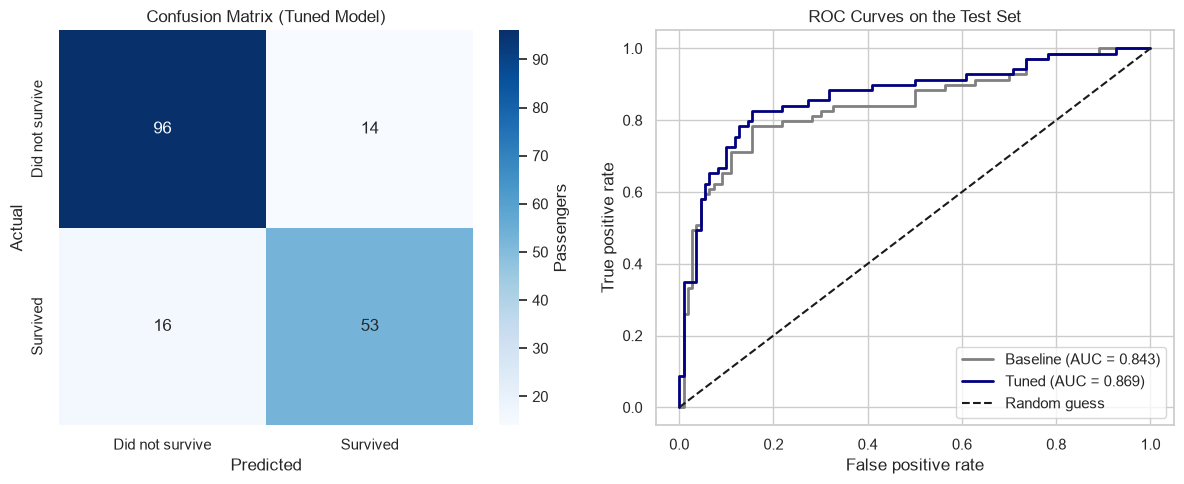

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", xticklabels=order,
            yticklabels=order, ax=axes[0], cbar_kws={"label": "Passengers"})
axes[0].set_title("Confusion Matrix (Tuned Model)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
for name, model, color in [("Baseline", baseline, "grey"), ("Tuned", tuned, "navy")]:
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curves on the Test Set")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/cs3_07_confusion_roc.png", dpi=150)
plt.show()

**Observation:** The tuned model gets 96 non-survivors and 53 survivors right. It makes 14 false positives (predicted to survive but died) and 16 false negatives (survived but predicted to die). Its ROC curve is above the baseline's for most of the range (AUC 0.869 vs 0.843).

### What the metrics mean

- **Accuracy (0.8324):** 149 of 179 test passengers are classified correctly. Always guessing "did not survive" would give 61.45%.
- **Precision (0.7910):** when the model says "survived", it is right about 79% of the time.
- **Recall (0.7681):** it finds about 77% of the real survivors.
- **F1 (0.7794):** combines precision and recall into one number.
- **ROC-AUC (0.8688):** how well the model ranks survivors above non-survivors, regardless of the 0.5 cut-off.

## A5. Interpretation

**Purpose:** Coefficients and odds ratios of the tuned model, sorted by size.

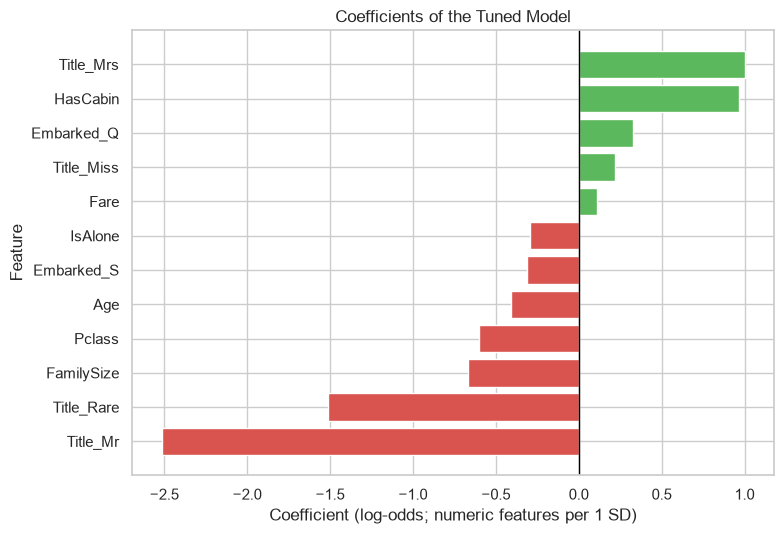

,feature,coefficient,odds_ratio
9,Title_Mr,-2.5167,0.0807
11,Title_Rare,-1.5152,0.2198
10,Title_Mrs,1.0018,2.7232
5,HasCabin,0.9639,2.6219
3,FamilySize,-0.6704,0.5115
0,Pclass,-0.6028,0.5473
1,Age,-0.4112,0.6629
6,Embarked_Q,0.3278,1.3879
7,Embarked_S,-0.3120,0.7320
4,IsAlone,-0.2963,0.7435


In [20]:
names = [n.split("__")[1] for n in tuned.named_steps["prep"].get_feature_names_out()]
coefs = tuned.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coefficient": coefs.round(4), "odds_ratio": np.exp(coefs).round(4)})
coef_df = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index)
coef_df.to_csv("results/cs3_coefficients.csv", index=False)

plot_df = coef_df.sort_values("coefficient")
plt.figure(figsize=(8, 5.5))
plt.barh(plot_df["feature"], plot_df["coefficient"], color=["#d9534f" if c < 0 else "#5cb85c" for c in plot_df["coefficient"]])
plt.axvline(0, color="black", lw=1)
plt.title("Coefficients of the Tuned Model")
plt.xlabel("Coefficient (log-odds; numeric features per 1 SD)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/cs3_08_coefficients.png", dpi=150)
plt.show()
coef_df

**Observation:** Title_Mr has the biggest effect (odds ratio 0.0807): compared with boys (Master), a man's odds of survival are about 8% as large. Title_Rare also lowers the odds (0.2198), while Title_Mrs (2.7232) and HasCabin (2.6219) raise them. A larger family, a lower class (higher Pclass number) and older age all lower the odds. Fare has the smallest effect.

**Purpose:** p-values and 95% confidence intervals from statsmodels, fitted on the same preprocessed training data.

In [21]:
X_train_t = pd.DataFrame(tuned.named_steps["prep"].transform(X_train), columns=names, index=X_train.index).astype(float)
logit = sm.Logit(y_train, sm.add_constant(X_train_t)).fit(disp=0)
ci = logit.conf_int()
sig = pd.DataFrame({"coef": logit.params, "p_value": logit.pvalues, "ci_low": ci[0], "ci_high": ci[1]}).round(4)
sig["significant"] = sig["p_value"] < 0.05
sig.to_csv("results/cs3_significance.csv")
json.dump({"pseudo_r2": round(logit.prsquared, 4), "llr_pvalue": float(logit.llr_pvalue)},
          open("results/cs3_logit_fit.json", "w"), indent=2)
print("Pseudo R-squared:", round(logit.prsquared, 4), " LLR p-value:", f"{logit.llr_pvalue:.2e}")
sig

Pseudo R-squared: 0.3892  LLR p-value: 1.37e-71


,coef,p_value,ci_low,ci_high,significant
const,1.1964,0.0604,-0.0521,2.4449,False
Pclass,-0.6102,0.0004,-0.9486,-0.2717,True
Age,-0.3811,0.0052,-0.6485,-0.1136,True
Fare,0.1075,0.4496,-0.1712,0.3863,False
FamilySize,-0.7317,0.0001,-1.1075,-0.3559,True
IsAlone,-0.3226,0.3483,-0.9967,0.3515,False
HasCabin,0.9710,0.0056,0.2838,1.6582,True
Embarked_Q,0.3043,0.5002,-0.5804,1.1889,False
Embarked_S,-0.3283,0.2356,-0.8707,0.2142,False
Title_Miss,-0.1320,0.8126,-1.2228,0.9589,False


**Observation:** The model as a whole is significant (p = 1.37e-71, pseudo R-squared 0.3892). Significant at 0.05: Title_Mr, FamilySize, Pclass, Age, HasCabin and Title_Rare. Not significant: Fare, IsAlone, Embarked, Title_Miss and Title_Mrs. Fare adds little once class is known, and Mrs/Miss are not significantly different from boys, which fits "women and children first".

## A6. Deployment

**Purpose:** Save the tuned pipeline and test it on three example passengers in the same format the app uses.

In [22]:
joblib.dump(tuned, "3/model/titanic_logreg.joblib")
examples = pd.DataFrame([
    {"Pclass": 3, "Age": 22, "Fare": 7.25, "Embarked": "S", "Title": "Mr", "FamilySize": 2, "IsAlone": 0, "HasCabin": 0},
    {"Pclass": 1, "Age": 38, "Fare": 71.28, "Embarked": "C", "Title": "Mrs", "FamilySize": 2, "IsAlone": 0, "HasCabin": 1},
    {"Pclass": 3, "Age": 4, "Fare": 16.7, "Embarked": "S", "Title": "Master", "FamilySize": 3, "IsAlone": 0, "HasCabin": 0}])
examples["survival_probability"] = joblib.load("3/model/titanic_logreg.joblib").predict_proba(examples)[:, 1].round(4)
examples

,Pclass,Age,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin,survival_probability
0,3,22,7.25,S,Mr,2,0,0,0.0824
1,1,38,71.28,C,Mrs,2,0,1,0.9699
2,3,4,16.70,S,Master,3,0,0,0.5682


**Observation:** The model is saved and works on new inputs. A 22-year-old 3rd class man gets 0.0824, a 38-year-old 1st class woman with a cabin gets 0.9699, and a 4-year-old boy in 3rd class gets 0.5682. These match what the EDA showed.

**Streamlit app (`3/app.py`).** The app loads the saved model and asks for class, sex, title, age, SibSp, Parch, fare, port and whether a cabin is known. It works out FamilySize and IsAlone itself and shows the survival probability and the predicted class.

Run it from the repository folder:
```
streamlit run 3/app.py
```
To put it online, use Streamlit Community Cloud with main file path `3/app.py`.

# Part B: Case Study 6, Bank Marketing Classification

I use `bank-additional-full.csv` instead of the older `bank-full.csv` because it is the newer UCI version and has five extra economic indicators (employment rate, consumer prices, consumer confidence, Euribor rate, number of employees).

## Task 1: Data Understanding and Preprocessing

**Purpose:** Load the data (separator `;`), show the first 10 rows and the shape.

In [23]:
bank = pd.read_csv("6/bank+marketing/bank-additional/bank-additional/bank-additional-full.csv", sep=";")
print(bank.shape)
bank.head(10)

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Observation:** The data has 41,188 rows and 21 columns. The first rows are all from May, and the economic columns repeat because they are monthly national values.

**Purpose:** Data types and summary statistics.

In [24]:
print(bank.dtypes.value_counts())
desc = bank.describe().T.round(3)
desc.to_csv("results/cs6_summary_numeric.csv")
desc

str        11
int64       5
float64     5
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100


**Observation:** There are 10 numeric and 11 text columns. Ages range from 17 to 98 (median 38). pdays is 999 for most rows, so its mean (962.475) is misleading. Euribor ranges from 0.634 to 5.045, showing big changes in the economy.

**Purpose:** List the numerical, categorical and target attributes.

In [25]:
numerical = ["age", "duration", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx",
             "cons.conf.idx", "euribor3m", "nr.employed"]
categorical = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
print("Numerical:", numerical)
print("Categorical:", categorical)
print("Target: y", sorted(bank["y"].unique()))

Numerical: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target: y ['no', 'yes']


**Observation:** There are 10 numerical attributes, 10 categorical attributes and the target y (no/yes).

**Purpose:** Count missing values and the "unknown" label in each categorical column.

In [26]:
print("NaN values:", bank.isna().sum().sum())
unknown = (bank[categorical] == "unknown").sum()
unknown = pd.DataFrame({"unknown": unknown, "percent": (unknown / len(bank) * 100).round(2)})
unknown = unknown[unknown["unknown"] > 0].sort_values("unknown", ascending=False)
unknown.to_csv("results/cs6_unknown.csv")
unknown

NaN values: 0


,unknown,percent
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


**Observation:** There are no NaN values, but "unknown" appears in six columns. It is most common in `default` (8,597 rows, 20.87%).

I keep "unknown" as its own category. Deleting those rows would remove over 20% of the data, and the unknown group can behave differently (for example, customers with an unknown `default` status subscribe less often).

**Purpose:** Remove duplicate rows.

In [27]:
print("Duplicates:", bank.duplicated().sum())
bank = bank.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", bank.shape)

Duplicates: 12
Shape after removing duplicates: (41176, 21)


**Observation:** I removed 12 duplicate rows, which leaves 41,176.

**pdays = 999** means the client has no previous contact recorded. As a number, 999 is misleading (it looks like a very old contact and it distorts scaling and distances). So I replace pdays with:
- `previously_contacted` = 1 if pdays is not 999,
- `pdays_contacted` = pdays for contacted clients and 0 for the rest.

**Purpose:** Check the 999 values and create the two new columns.

In [28]:
never = bank["pdays"] == 999
print("pdays = 999:", never.sum(), f"({never.mean() * 100:.2f}%)")
print("Real pdays values range from", bank.loc[~never, "pdays"].min(), "to", bank.loc[~never, "pdays"].max())
print(pd.crosstab(never, bank["poutcome"]))
bank["previously_contacted"] = (~never).astype(int)
bank["pdays_contacted"] = bank["pdays"].where(~never, 0)
bank = bank.drop(columns="pdays")

pdays = 999: 39661 (96.32%)
Real pdays values range from 0 to 27
poutcome  failure  nonexistent  success
pdays                                  
False         142            0     1373
True         4110        35551        0


**Observation:** 96.32% of rows have pdays = 999. Real values only go from 0 to 27 days. All previous successes have a real pdays value, but 4,110 previous failures also have 999, so 999 really means "no contact date recorded".

**Purpose:** Target distribution.

In [29]:
target = pd.DataFrame({"count": bank["y"].value_counts(), "percent": (bank["y"].value_counts(normalize=True) * 100).round(2)})
target.to_csv("results/cs6_target.csv")
target

,count,percent
y,,
no,36537,88.73
yes,4639,11.27


**Observation:** Only 11.27% of customers subscribed (4,639 yes vs 36,537 no). The data is very imbalanced, so accuracy alone is not a good measure.

**duration is dropped from the models.** It is the length of the call, which is only known after the call has happened. By then we already know the result, so using it would be data leakage (the UCI notes say the same). I only use it in one EDA plot.

**Purpose:** Map y to 1/0, choose the model features without duration, make one stratified 80:20 split and build the shared preprocessor.

In [30]:
bank["y"] = bank["y"].map({"yes": 1, "no": 0})
num_features = ["age", "campaign", "previous", "pdays_contacted", "emp.var.rate", "cons.price.idx",
                "cons.conf.idx", "euribor3m", "nr.employed"]
Xb = bank[num_features + ["previously_contacted"] + categorical]
yb = bank["y"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=RANDOM_STATE)
print("Train:", Xb_train.shape, " Test:", Xb_test.shape)
print("Subscribers in test set:", yb_test.sum(), "of", len(yb_test))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("flag", "passthrough", ["previously_contacted"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])

Train:

 (32940, 20)  Test: (8236, 20)
Subscribers in test set: 928 of 8236


**Observation:** There are 32,940 training and 8,236 test customers. The test set has 928 subscribers. duration is not in the features.

## Task 2: Exploratory Data Analysis

**Purpose:** Bar chart of the target with counts and percentages.

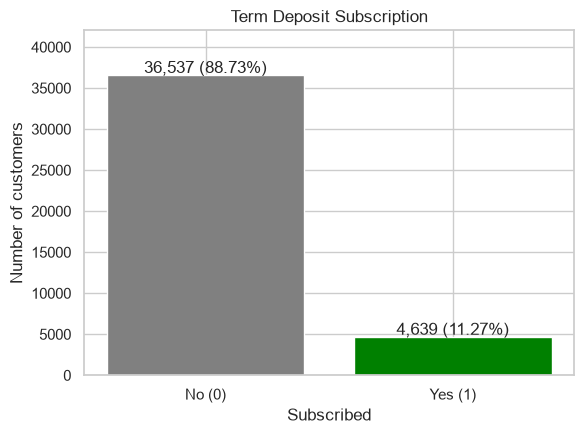

In [31]:
counts = bank["y"].value_counts().sort_index()
plt.figure(figsize=(6, 4.5))
bars = plt.bar(["No (0)", "Yes (1)"], counts.values, color=["grey", "green"])
for b, c in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width() / 2, c + 300, f"{c:,} ({c / counts.sum() * 100:.2f}%)", ha="center")
plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of customers")
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("figures/cs6_01_target.png", dpi=150)
plt.show()

**Observation:** The chart shows the imbalance clearly: 88.73% no and 11.27% yes.

**Purpose:** Subscription rate (% yes) by job, month, education, contact, poutcome and previously_contacted.

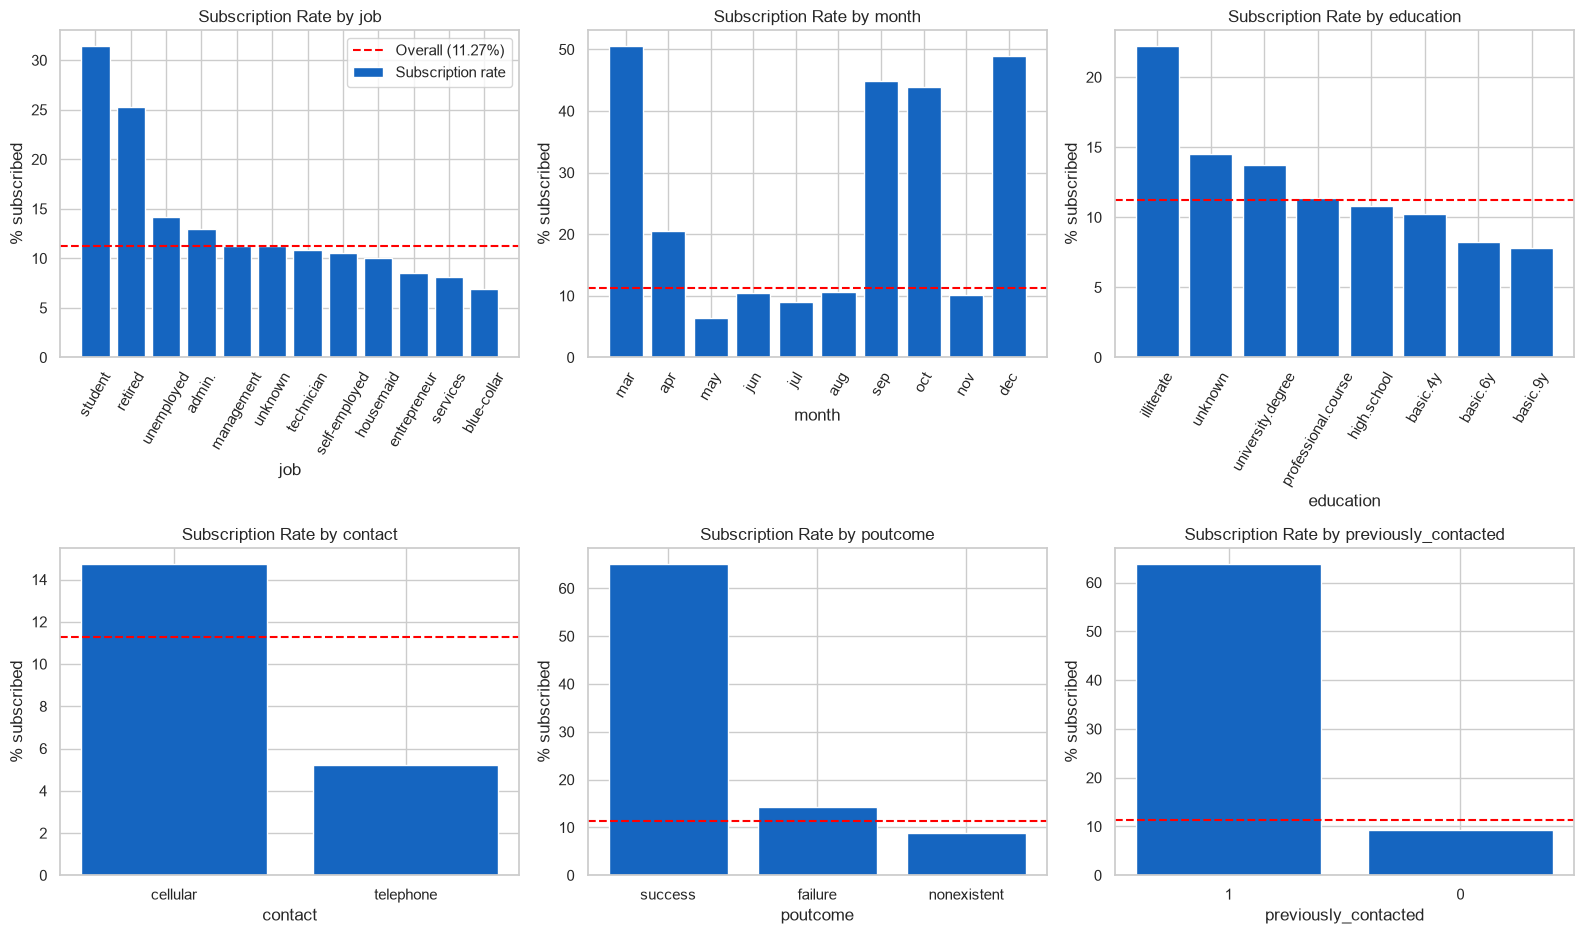

                     count   rate               feature
student                875  31.43                   job
retired               1718  25.26                   job
unemployed            1014  14.20                   job
admin.               10419  12.97                   job
management            2924  11.22                   job
unknown                330  11.21                   job
technician            6739  10.83                   job
self-employed         1421  10.49                   job
housemaid             1060  10.00                   job
entrepreneur          1456   8.52                   job
services              3967   8.14                   job
blue-collar           9253   6.90                   job
mar                    546  50.55                 month
apr                   2631  20.49                 month
may                  13767   6.44                 month
jun                   5318  10.51                 month
jul                   7169   9.04               

In [32]:
overall = bank["y"].mean() * 100
months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
all_rates = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, col in zip(axes.ravel(), ["job", "month", "education", "contact", "poutcome", "previously_contacted"]):
    t = bank.groupby(col)["y"].agg(["count", "mean"])
    t["rate"] = (t["mean"] * 100).round(2)
    t = t.reindex(months) if col == "month" else t.sort_values("rate", ascending=False)
    all_rates.append(t[["count", "rate"]].assign(feature=col))
    ax.bar(t.index.astype(str), t["rate"], color="#1565c0", label="Subscription rate")
    ax.axhline(overall, color="red", ls="--", label=f"Overall ({overall:.2f}%)")
    ax.set_title(f"Subscription Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("% subscribed")
    ax.tick_params(axis="x", rotation=60 if col in ["job", "month", "education"] else 0)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("figures/cs6_02_rates.png", dpi=150)
plt.show()
rates = pd.concat(all_rates)
rates.to_csv("results/cs6_rates.csv")
print(rates.to_string())

**Observation:** Students (31.43%) and retired people (25.26%) subscribe the most and blue-collar workers the least (6.90%). March, September, October and December have rates above 40% but few calls, while May had the most calls (13,767) and the lowest rate (6.44%). Cellular contact works better than telephone (14.74% vs 5.23%). Customers contacted before subscribe at 63.83%, against 9.26% for the rest.

**Purpose:** Box plots of age, campaign, euribor3m and nr.employed by outcome, plus duration (EDA only).

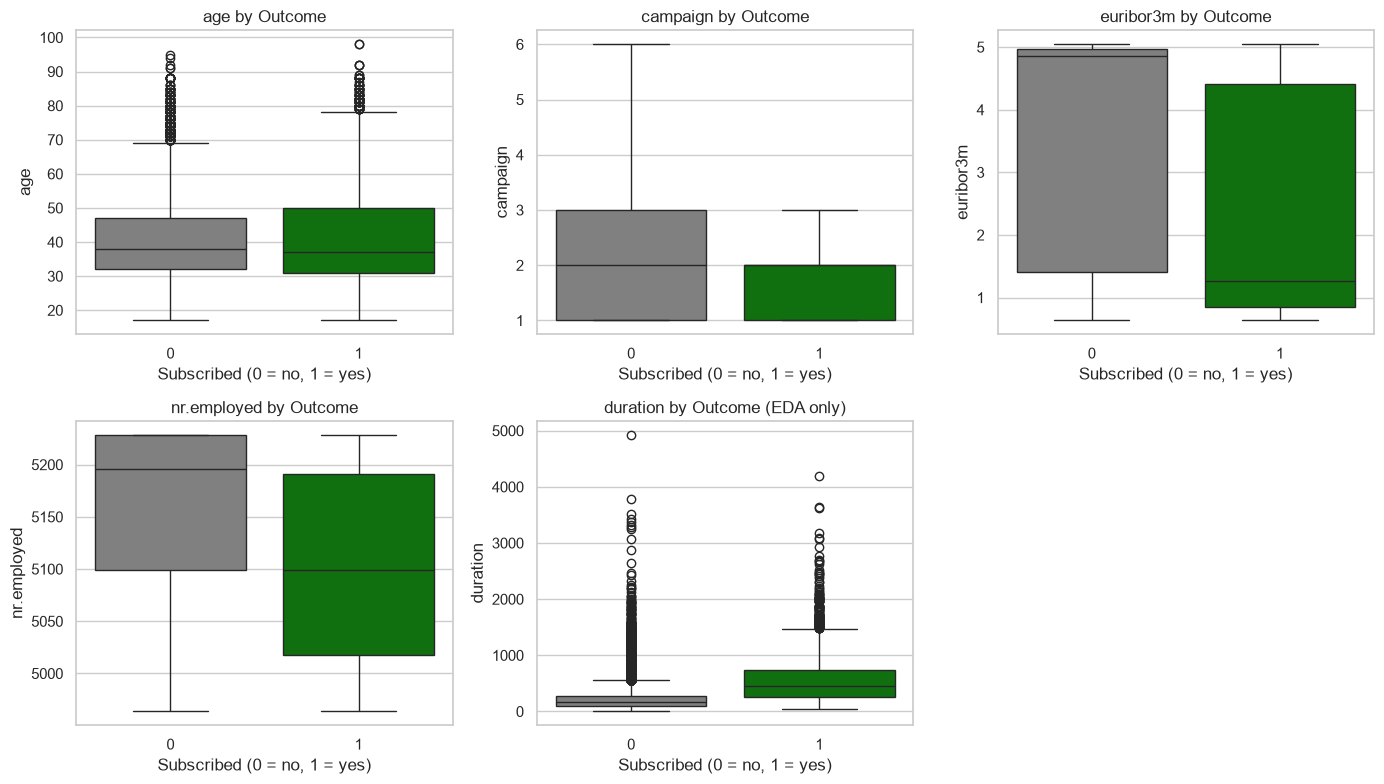

y                          0         1
age         median    38.000    37.000
            mean      39.911    40.912
campaign    median     2.000     2.000
            mean       2.633     2.052
euribor3m   median     4.857     1.266
            mean       3.811     2.123
nr.employed median  5195.800  5099.100
            mean    5176.166  5095.120
duration    median   164.000   449.000
            mean     220.868   553.256

In [33]:
box_cols = ["age", "campaign", "euribor3m", "nr.employed", "duration"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=bank, x="y", y=col, hue="y", palette=["grey", "green"], legend=False, ax=ax,
                showfliers=(col != "campaign"))
    ax.set_title(f"{col} by Outcome" + (" (EDA only)" if col == "duration" else ""))
    ax.set_xlabel("Subscribed (0 = no, 1 = yes)")
    ax.set_ylabel(col)
axes[1, 2].axis("off")
plt.tight_layout()
plt.savefig("figures/cs6_03_boxplots.png", dpi=150)
plt.show()
medians = bank.groupby("y")[box_cols].agg(["median", "mean"]).T.round(3)
medians.to_csv("results/cs6_numeric_by_outcome.csv")
medians

**Observation:** Age is about the same in both groups (median 38 vs 37). Subscribers had fewer calls on average (2.05 vs 2.63). Euribor and the number of employees were much lower for subscribers (median Euribor 1.266 vs 4.857). Duration is much longer for subscribers (449 s vs 164 s), but it can't be used before the call.

### EDA observations

1. Customers with a previous contact subscribe at 63.83%, and after a previous success at 65.11%, against 11.27% overall.
2. People subscribed more when interest rates were low: the median Euribor was 1.266 for subscribers vs 4.857 for non-subscribers.
3. Timing and channel matter: May had the most calls but the lowest rate (6.44%), and cellular converts better than telephone (14.74% vs 5.23%).
4. Students (31.43%) and retired customers (25.26%) are the best segments.

## Task 3: Model Development

All four models use the same preprocessor and the same split. I tune each one with GridSearchCV (stratified 3-fold CV on the training set, scoring F1 for the "yes" class). F1 balances finding subscribers (recall) and not wasting calls (precision).

| Model | Fixed settings | Values tried |
|---|---|---|
| Logistic Regression | max_iter=1000, class_weight="balanced" | C: 0.01, 0.1, 1, 10 |
| Decision Tree | class_weight="balanced" | max_depth: 4, 6, 8, 10, 12; min_samples_leaf: 1, 20, 50, 100 |
| KNN | none (KNN has no class_weight option) | n_neighbors: 5, 15, 25, 51; weights: uniform, distance |
| Random Forest | class_weight="balanced" | n_estimators: 200, 400; max_depth: 8, 12, None; min_samples_leaf: 1, 5, 10 |

`class_weight="balanced"` gives more weight to the rare "yes" class.

**Purpose:** Tune and evaluate all four models in one loop and collect the results in one table.

In [34]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
                            {"C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"max_depth": [4, 6, 8, 10, 12], "min_samples_leaf": [1, 20, 50, 100]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [5, 15, 25, 51], "weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"n_estimators": [200, 400], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5, 10]}),
}
results, fitted, probs, matrices = [], {}, {}, {}
for name, (clf, params) in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    search = GridSearchCV(pipe, {f"clf__{k}": v for k, v in params.items()}, cv=cv3, scoring="f1", n_jobs=-1)
    search.fit(Xb_train, yb_train)
    best = search.best_estimator_
    prob = best.predict_proba(Xb_test)[:, 1]
    pred = best.predict(Xb_test)
    tn, fp, fn, tp = confusion_matrix(yb_test, pred).ravel()
    best_params = ", ".join(f"{k.replace('clf__', '')}={v}" for k, v in search.best_params_.items())
    results.append([name, best_params, round(search.best_score_, 4), accuracy_score(yb_test, pred),
                    precision_score(yb_test, pred), recall_score(yb_test, pred), f1_score(yb_test, pred),
                    roc_auc_score(yb_test, prob), tn, fp, fn, tp])
    fitted[name], probs[name], matrices[name] = best, prob, confusion_matrix(yb_test, pred)
    print(f"{name}: best {best_params} (CV F1 {search.best_score_:.4f})")

comparison = pd.DataFrame(results, columns=["model", "best_params", "cv_f1", "accuracy", "precision", "recall",
                                            "f1", "roc_auc", "TN", "FP", "FN", "TP"]).set_index("model").round(4)

Logistic Regression: best C=10 (CV F1 0.4498)


Decision Tree: best max_depth=4, min_samples_leaf=20 (CV F1 0.4581)


KNN: best n_neighbors=5, weights=uniform (CV F1 0.3730)


Random Forest: best max_depth=12, min_samples_leaf=1, n_estimators=200 (CV F1 0.4835)


**Observation:** The best settings are C=10 for Logistic Regression, max_depth=4 with min_samples_leaf=20 for the Decision Tree, k=5 (uniform) for KNN, and 200 trees with max_depth=12 for the Random Forest. Random Forest has the highest CV F1 (0.4835) and KNN the lowest (0.3730).

## Task 4: Model Comparison

**Purpose:** Final comparison table, saved to `results/cs6_model_comparison.csv`.

In [35]:
comparison["subscribers_caught"] = comparison["TP"].astype(str) + " / " + (comparison["TP"] + comparison["FN"]).astype(str)
comparison.to_csv("results/cs6_model_comparison.csv")
comparison.drop(columns="best_params")

,cv_f1,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP,subscribers_caught
model,,,,,,,,,,,
Logistic Regression,0.4498,0.8298,0.3583,0.6455,0.4608,0.8001,6235,1073,329,599,599 / 928
Decision Tree,0.4581,0.8462,0.3862,0.6196,0.4758,0.7852,6394,914,353,575,575 / 928
KNN,0.3730,0.8950,0.5639,0.2996,0.3913,0.7407,7093,215,650,278,278 / 928
Random Forest,0.4835,0.8609,0.4218,0.6336,0.5065,0.8134,6502,806,340,588,588 / 928


**Observation:** Random Forest has the best F1 (0.5065) and ROC-AUC (0.8134). Logistic Regression has the highest recall (0.6455) but the lowest precision (0.3583). KNN has the highest accuracy (0.8950) but finds only 278 of 928 subscribers.

**Purpose:** Grouped bar chart of accuracy, precision, recall and F1.

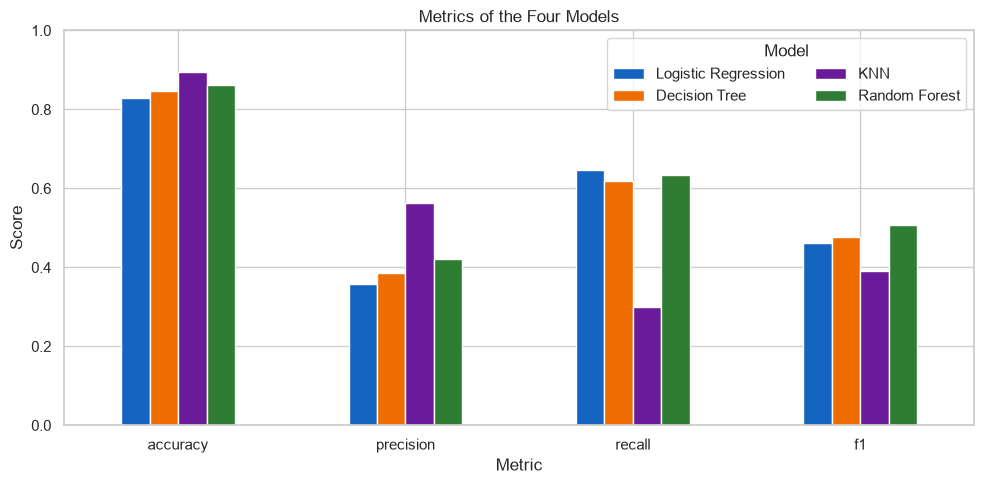

In [36]:
metrics = ["accuracy", "precision", "recall", "f1"]
comparison[metrics].T.plot(kind="bar", figsize=(10, 5), color=["#1565c0", "#ef6c00", "#6a1b9a", "#2e7d32"])
plt.title("Metrics of the Four Models")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Model", ncol=2)
plt.tight_layout()
plt.savefig("figures/cs6_04_metrics.png", dpi=150)
plt.show()

**Observation:** Accuracy is high for every model, so it doesn't tell them apart. Recall and F1 show the real differences: KNN is much lower on recall, and Random Forest has the highest F1.

**Purpose:** Confusion matrices of all four models in a 2x2 grid.

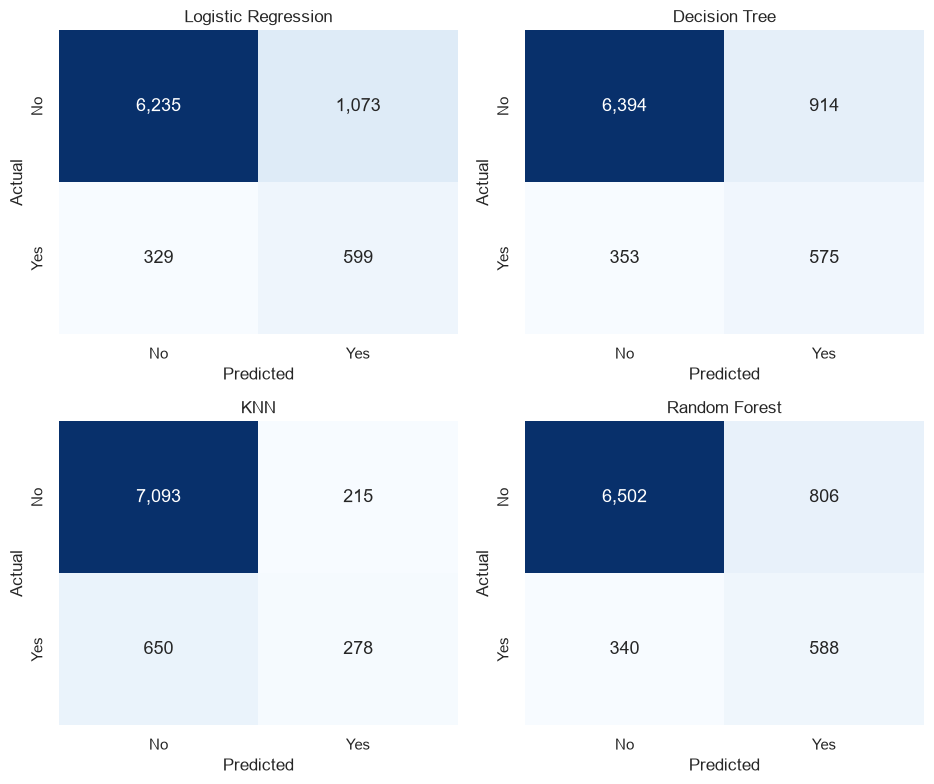

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 8))
for ax, name in zip(axes.ravel(), comparison.index):
    sns.heatmap(matrices[name], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], annot_kws={"size": 13})
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("figures/cs6_05_confusion.png", dpi=150)
plt.show()

**Observation:** Logistic Regression finds the most subscribers (599) but makes the most wasted calls (1,073 false positives). Random Forest finds 588 with only 806 false positives. KNN makes very few wasted calls (215) but misses 650 subscribers. For the bank, a missed subscriber (FN) is lost revenue, while a wasted call (FP) only costs some time.

**Purpose:** ROC curves of all four models on one plot.

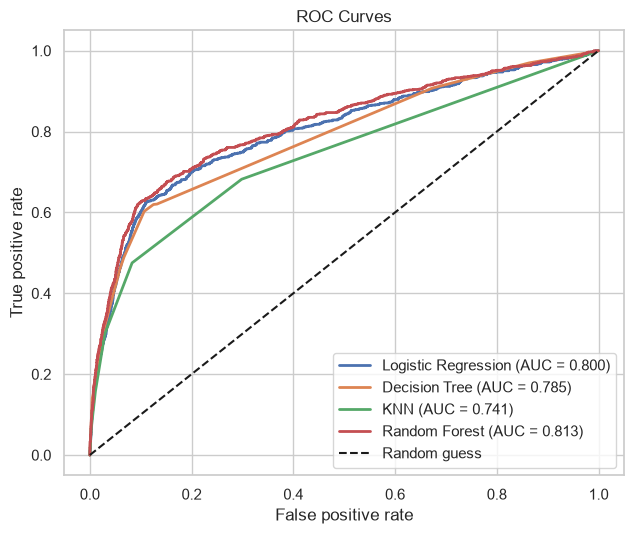

In [38]:
plt.figure(figsize=(6.5, 5.5))
for name in comparison.index:
    fpr, tpr, _ = roc_curve(yb_test, probs[name])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {comparison.loc[name, 'roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curves")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/cs6_06_roc.png", dpi=150)
plt.show()

**Observation:** Random Forest has the highest AUC (0.813), then Logistic Regression (0.800), Decision Tree (0.785) and KNN (0.741). All are well above random guessing.

**Purpose:** Cumulative gains for the Random Forest: what % of subscribers we reach by calling the top 10%, 20% and 30% of customers by score.

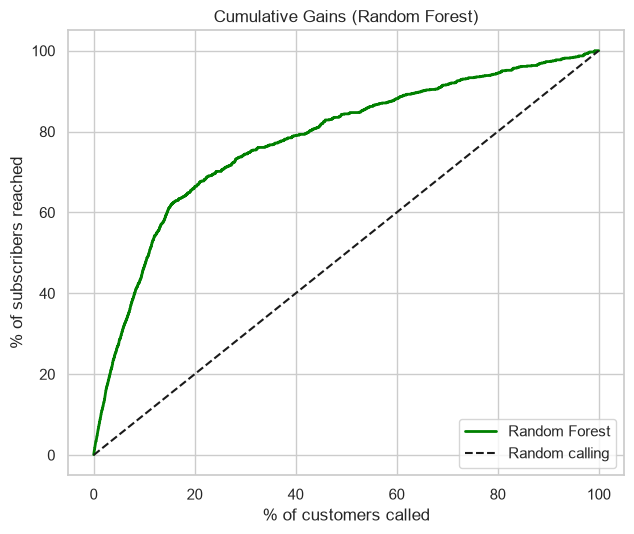

,top_10%,top_20%,top_30%,top_50%
Logistic Regression,44.72,64.44,73.06,82.33
Decision Tree,45.26,62.82,69.18,80.28
KNN,39.98,54.42,64.98,76.08
Random Forest,46.55,66.38,74.46,84.38


In [39]:
gains = {}
for name in comparison.index:
    order_idx = np.argsort(-probs[name])
    found = np.cumsum(yb_test.values[order_idx]) / yb_test.sum() * 100
    gains[name] = {f"top_{p}%": round(found[int(np.ceil(len(found) * p / 100)) - 1], 2) for p in (10, 20, 30, 50)}
gains = pd.DataFrame(gains).T
gains.to_csv("results/cs6_gains.csv")

order_idx = np.argsort(-probs["Random Forest"])
found = np.cumsum(yb_test.values[order_idx]) / yb_test.sum() * 100
called = np.arange(1, len(found) + 1) / len(found) * 100
plt.figure(figsize=(6.5, 5.5))
plt.plot(called, found, color="green", lw=2, label="Random Forest")
plt.plot([0, 100], [0, 100], "k--", label="Random calling")
plt.title("Cumulative Gains (Random Forest)")
plt.xlabel("% of customers called")
plt.ylabel("% of subscribers reached")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/cs6_07_gains.png", dpi=150)
plt.show()
gains

**Observation:** If the bank calls the top 10% of customers ranked by the Random Forest, it reaches 46.55% of subscribers. The top 20% reaches 66.38% and the top 30% reaches 74.46%. Random Forest is the best model at every cut-off.

**Purpose:** Top 15 feature importances of the Random Forest.

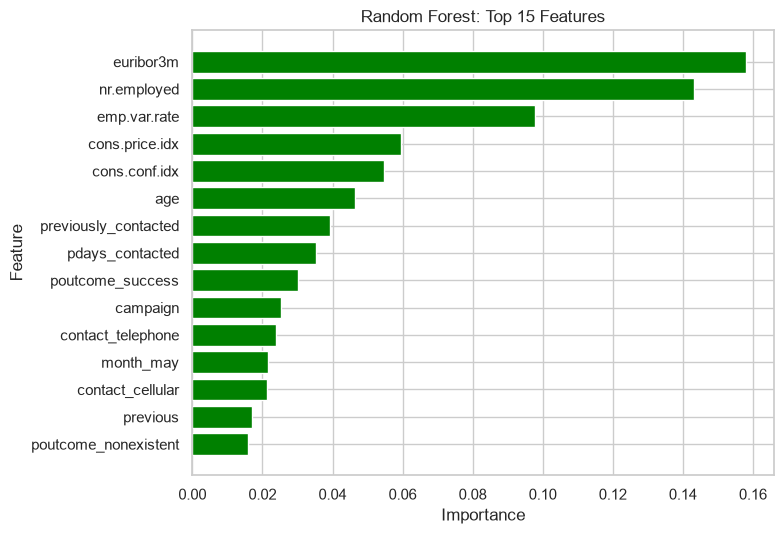

Share of the 5 economic features: 0.5132


euribor3m               0.1581
nr.employed             0.1431
emp.var.rate            0.0978
cons.price.idx          0.0595
cons.conf.idx           0.0548
age                     0.0465
previously_contacted    0.0392
pdays_contacted         0.0352
poutcome_success        0.0302
campaign                0.0254
contact_telephone       0.0240
month_may               0.0217
contact_cellular        0.0212
previous                0.0170
poutcome_nonexistent    0.0159
dtype: float64

In [40]:
rf = fitted["Random Forest"]
names = [n.split("__")[1] for n in rf.named_steps["prep"].get_feature_names_out()]
importance = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
top15 = importance.head(15).round(4)
top15.to_csv("results/cs6_importance.csv")
plt.figure(figsize=(8, 5.5))
plt.barh(top15.index[::-1], top15.values[::-1], color="green")
plt.title("Random Forest: Top 15 Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/cs6_08_importance.png", dpi=150)
plt.show()
econ = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("Share of the 5 economic features:", round(importance[econ].sum(), 4))
top15

**Observation:** The economic features matter most: euribor3m, nr.employed and emp.var.rate are the top three, and the five economic features together hold 51% of the importance. Age, previously_contacted and pdays_contacted come next.

### Choosing the best model

I don't pick the model by accuracy, because predicting "no" for everyone would already give 88.73%. Missing a subscriber loses a sale, so recall matters, but precision also matters because every wasted call costs time.

- KNN misses too many subscribers (recall 0.2996).
- Logistic Regression finds only 11 more subscribers than Random Forest but makes 267 more wasted calls.
- Random Forest has the best F1 (0.5065), the best ROC-AUC (0.8134) and good recall (0.6336).

**Random Forest is the best model** for the bank.

## Task 5: Interpretation

### Business recommendations

1. Rank customers by the Random Forest score and call the top ones first. Calling the top 20% reaches about two thirds (66.38%) of all subscribers.
2. Focus on customers who were contacted before (63.83% subscribe), students and retired customers.
3. Prefer mobile phones over landlines, and run bigger campaigns when interest rates are low instead of making a huge number of calls in one month like May.
4. Don't keep calling the same person many times; subscribers needed fewer calls on average.

### Limitations

1. The data is from 2008 to 2010 (a financial crisis). The economic features matter most, so the model may not work as well today.
2. duration was removed to avoid leakage. This makes the model realistic, but precision is only about 0.42.
3. All results use the default 0.5 threshold, which may not be the best for the bank's costs.
4. The grids were small and I used a single train/test split, so close models like Logistic Regression and Random Forest could swap places on other data.

## Conclusion

**Case Study 3:** Sex, class and family size were the main factors in Titanic survival. Adding Title, FamilySize, IsAlone and HasCabin and tuning C improved the model from accuracy 0.8045 / ROC-AUC 0.8435 to 0.8324 / 0.8688, and it now finds 53 of 69 survivors instead of 46. The final model is saved and used in a Streamlit app.

**Case Study 6:** The bank data is very imbalanced (11.27% yes), so I compared the models on recall, precision, F1 and ROC-AUC instead of accuracy. After tuning, Random Forest was the best (F1 0.5065, ROC-AUC 0.8134). Calling its top 20% of customers reaches 66.38% of subscribers.